# 03 – Bivariate Analysis and Conclusions

**Objective:** analyse how `log(PRICE)` relates to each candidate feature, identify the most predictive variables, and draw conclusions for the modelling stage.

**Input:** `data/processed/listings_02.parquet` (output of notebook 02).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_02.parquet")

df["log_price"] = np.log(df["PRICE"])
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"log(PRICE) — mean: {df['log_price'].mean():.2f}, std: {df['log_price'].std():.2f}")

Loaded: 75,795 rows × 39 columns
log(PRICE) — mean: 12.54, std: 0.76


## 1. Continuous features vs log(PRICE)

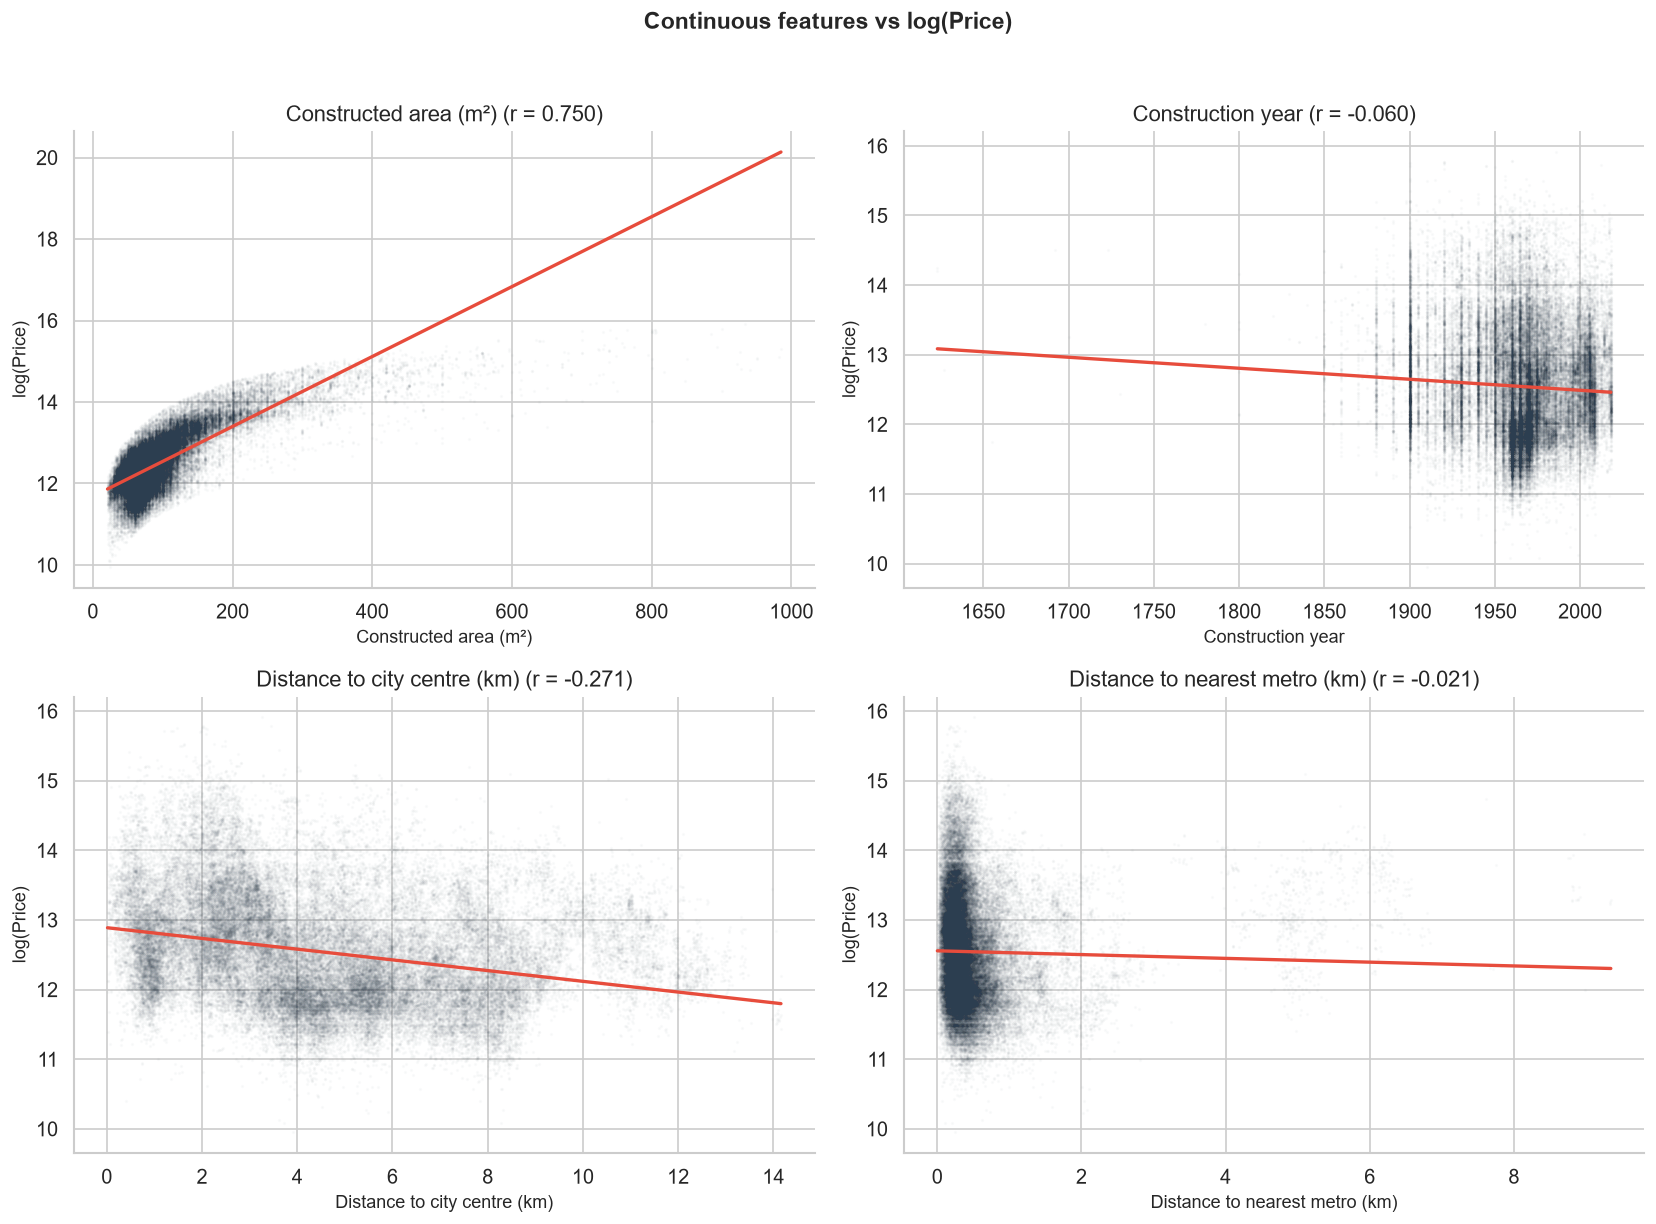

In [2]:
cont_features = ["CONSTRUCTEDAREA", "CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

readable = {
    "CONSTRUCTEDAREA": "Constructed area (m²)",
    "CADCONSTRUCTIONYEAR": "Construction year",
    "DISTANCE_TO_CITY_CENTER": "Distance to city centre (km)",
    "DISTANCE_TO_METRO": "Distance to nearest metro (km)",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feat in zip(axes.ravel(), cont_features):
    ax.scatter(df[feat], df["log_price"], alpha=0.02, s=1, color="#2c3e50")
    z = np.polyfit(df[feat].dropna(), df.loc[df[feat].notna(), "log_price"], 1)
    x_line = np.linspace(df[feat].min(), df[feat].max(), 100)
    ax.plot(x_line, np.polyval(z, x_line), color="#e74c3c", lw=2)
    r = df[feat].corr(df["log_price"])
    ax.set_title(f"{readable.get(feat, feat)} (r = {r:.3f})")
    ax.set_ylabel("log(Price)")
    ax.set_xlabel(readable.get(feat, feat))
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Continuous features vs log(Price)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

- **`CONSTRUCTEDAREA`** has the strongest relationship with log(PRICE) (r = 0.75): larger flats are more expensive. It will be the single most predictive feature.
- **`DISTANCE_TO_CITY_CENTER`** is negative but only moderate (r = −0.27). Location matters, but straight-line distance to the centre captures it only partly (see sections 4 and 5).
- **`CADCONSTRUCTIONYEAR`** has almost no *linear* relationship (r = −0.06), but the relationship is **U-shaped**: median price is 335k € for pre-1900 buildings, falls to 213k € for 1960–1980 buildings and rises again to 286k € after 2000. Historic central buildings and new developments are expensive; the 1960s–70s housing estates are the cheapest. A linear term will miss this → use construction-period bins or a tree-based model.
- **`DISTANCE_TO_METRO`** is very weak linearly (r = −0.02, Spearman −0.18): there is a small monotonic effect, but it is not a major driver.

## 2. Discrete and ordinal features vs log(PRICE)

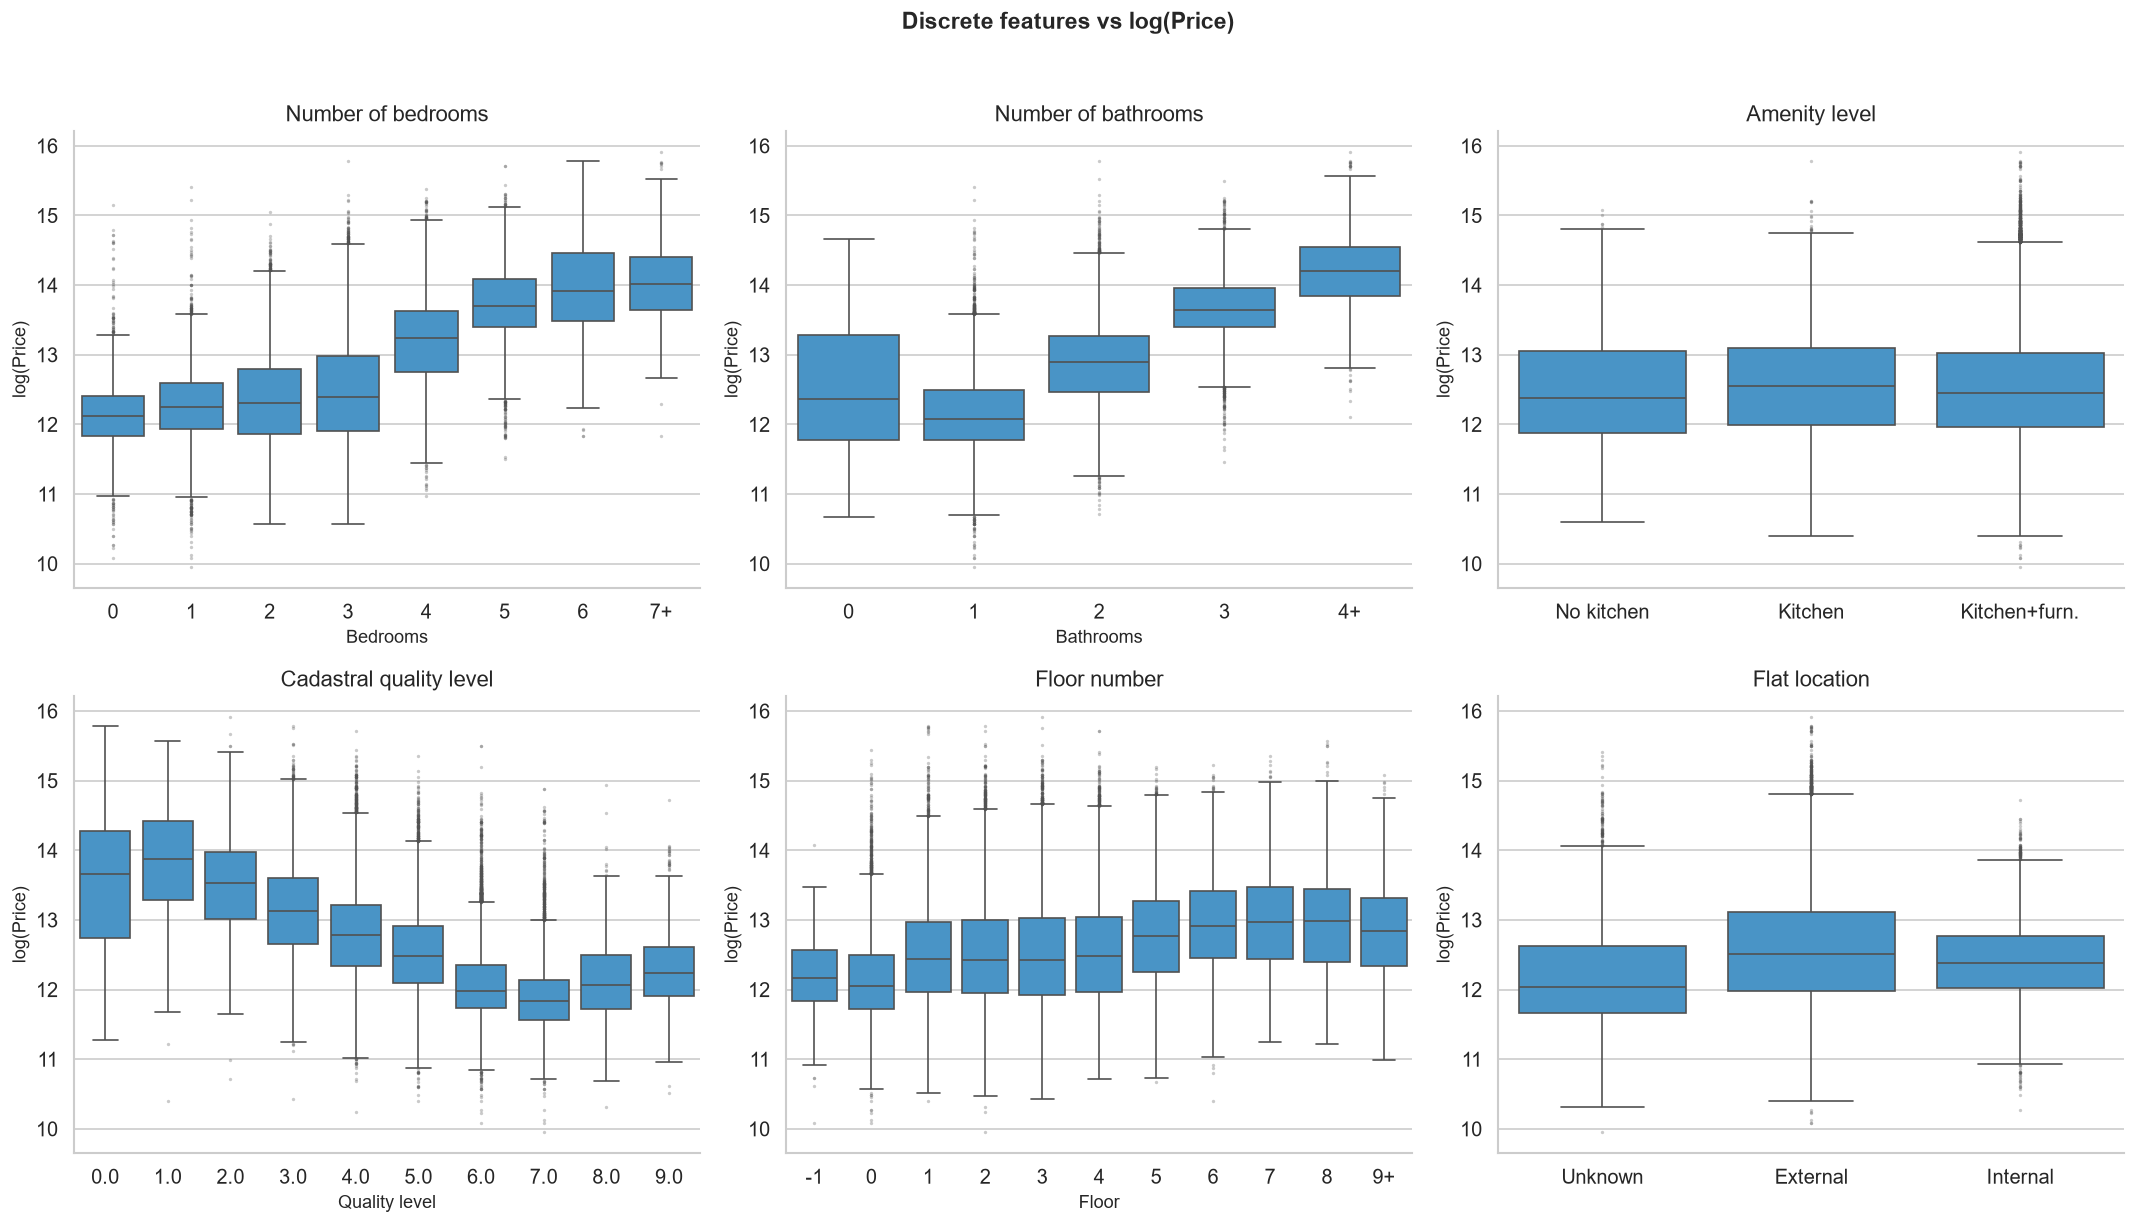

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ROOMNUMBER
room_data = df.copy()
room_data["ROOMNUMBER_grp"] = room_data["ROOMNUMBER"].clip(upper=7).astype(str)
room_data.loc[room_data["ROOMNUMBER"] >= 7, "ROOMNUMBER_grp"] = "7+"
sns.boxplot(x="ROOMNUMBER_grp", y="log_price", data=room_data, ax=axes[0, 0],
            order=[str(i) for i in range(7)] + ["7+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0, 0].set_title("Number of bedrooms")
axes[0, 0].set_xlabel("Bedrooms")

# BATHNUMBER
bath_data = df.copy()
bath_data["BATHNUMBER_grp"] = bath_data["BATHNUMBER"].clip(upper=4).astype(str)
bath_data.loc[bath_data["BATHNUMBER"] >= 4, "BATHNUMBER_grp"] = "4+"
sns.boxplot(x="BATHNUMBER_grp", y="log_price", data=bath_data, ax=axes[0, 1],
            order=[str(i) for i in range(4)] + ["4+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0, 1].set_title("Number of bathrooms")
axes[0, 1].set_xlabel("Bathrooms")

# AMENITYID (official docs: 1 = no kitchen/furniture, 2 = kitchen, 3 = kitchen + furniture)
amenity_labels = {1: "No kitchen", 2: "Kitchen", 3: "Kitchen+furn."}
amenity_data = df.copy()
amenity_data["AMENITYID_lbl"] = amenity_data["AMENITYID"].map(amenity_labels)
sns.boxplot(x="AMENITYID_lbl", y="log_price", data=amenity_data, ax=axes[0, 2],
            order=["No kitchen", "Kitchen", "Kitchen+furn."], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0, 2].set_title("Amenity level")
axes[0, 2].set_xlabel("")

# CADASTRALQUALITYID
sns.boxplot(x="CADASTRALQUALITYID", y="log_price", data=df, ax=axes[1, 0], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1, 0].set_title("Cadastral quality level")
axes[1, 0].set_xlabel("Quality level")

# FLOORCLEAN
floor_data = df.copy()
floor_data["FLOOR_grp"] = floor_data["FLOORCLEAN"].clip(-1, 8).astype(int).astype(str)
floor_data.loc[floor_data["FLOORCLEAN"] > 8, "FLOOR_grp"] = "9+"
sns.boxplot(x="FLOOR_grp", y="log_price", data=floor_data, ax=axes[1, 1],
            order=[str(i) for i in range(-1, 9)] + ["9+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1, 1].set_title("Floor number")
axes[1, 1].set_xlabel("Floor")

# FLATLOCATIONID (official docs: 1 = external, 2 = internal; 0 = not reported)
loc_labels = {0: "Unknown", 1: "External", 2: "Internal"}
loc_data = df.copy()
loc_data["LOC_lbl"] = loc_data["FLATLOCATIONID"].map(loc_labels)
sns.boxplot(x="LOC_lbl", y="log_price", data=loc_data, ax=axes[1, 2],
            order=["Unknown", "External", "Internal"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1, 2].set_title("Flat location")
axes[1, 2].set_xlabel("")

for ax in axes.ravel():
    ax.set_ylabel("log(Price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Discrete features vs log(Price)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

- **`ROOMNUMBER`** (bedrooms): median price rises slowly from 0 to 3 bedrooms (184k € → 242k €) and then **jumps** from 4 bedrooms on (563k €; 1.22M € for 7+). It does not flatten. Part of this effect is size (r with area = 0.65).
- **`BATHNUMBER`** is a stronger signal than bedrooms (r = 0.70 vs 0.46): 1 bathroom → 177k €, 2 → 400k €, 3 → 838k €, 4+ → 1.47M €.
- **`CADASTRALQUALITYID`**: **lower level = more expensive** (r = −0.57). The median falls from 1,061,000 € at level 1 to 138,000 € at level 7. It is not perfectly monotonic: level 0 (311 listings) is slightly below level 1, and levels 8–9 rebound a little (175k €, 207k €). It is still one of the most informative features.
- **`AMENITYID`** is **not** ordinal in price: no kitchen 238k €, kitchen 281k €, kitchen + furniture 256k €. Since 94.1% of listings are level 3 (r ≈ −0.01), it carries little information.
- **`FLOORCLEAN`**: the **ground floor (0) is the cheapest** (171.5k €), below the basement (−1, 192k €), and prices rise with height up to ~435k € at floor 8 (r = 0.23).
- **`FLATLOCATIONID`**: external flats (273k €) are more expensive than internal ones (239k €). Listings that do **not report** the location (0) are the **cheapest** (170k €), not "in between", so the missing value itself carries information and 0 should be kept as its own category.

## 3. Binary features vs log(PRICE)

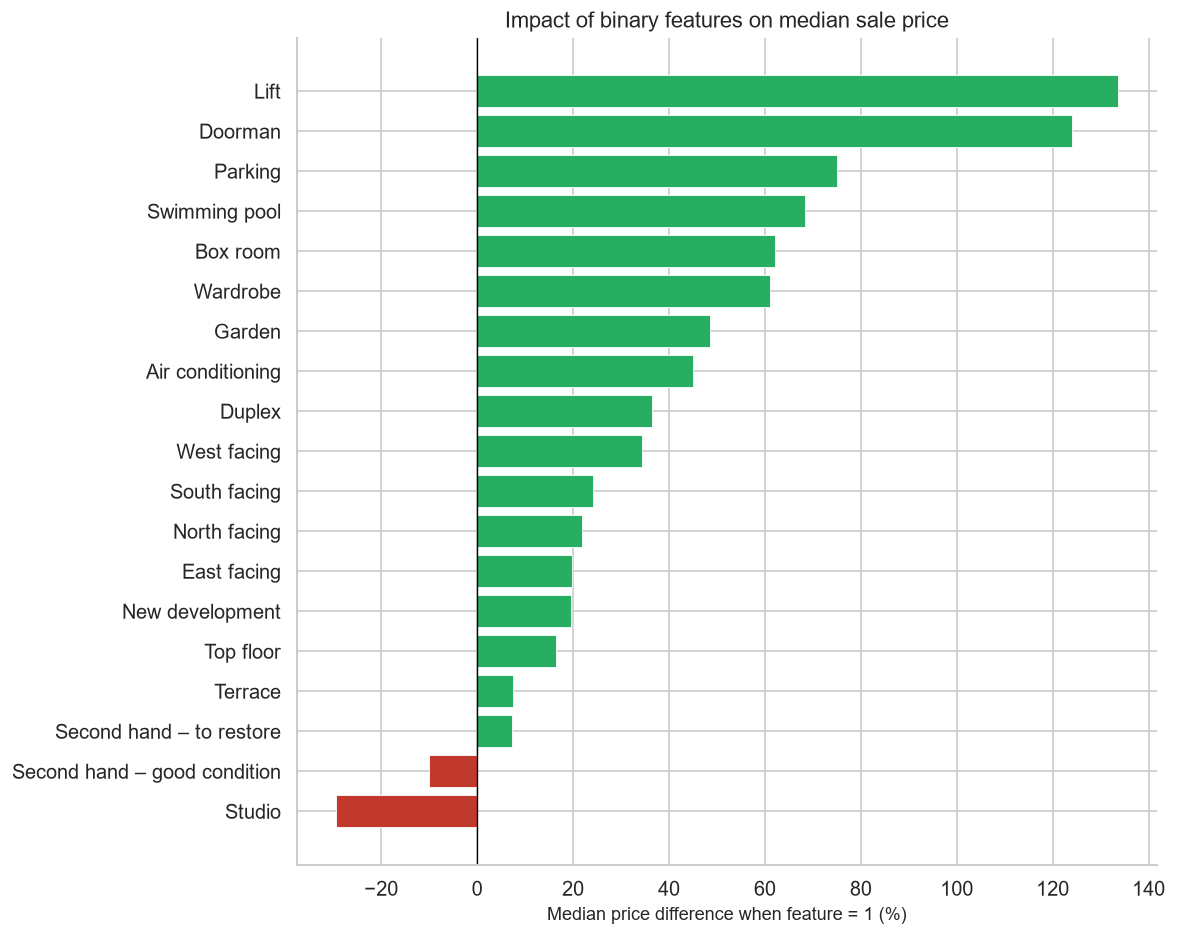

ISSTUDIO               -29.4
BUILTTYPEID_3          -10.0
BUILTTYPEID_2            7.3
HASTERRACE               7.6
ISINTOPFLOOR            16.4
BUILTTYPEID_1           19.6
HASEASTORIENTATION      19.8
HASNORTHORIENTATION     21.8
HASSOUTHORIENTATION     24.1
HASWESTORIENTATION      34.4
ISDUPLEX                36.5
HASAIRCONDITIONING      45.0
HASGARDEN               48.5
HASWARDROBE             61.0
HASBOXROOM              62.1
HASSWIMMINGPOOL         68.4
HASPARKINGSPACE         75.0
HASDOORMAN             123.9
HASLIFT                133.6
dtype: float64


In [4]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

price_diff = {}
for col in binary_cols:
    median_0 = df.loc[df[col] == 0, "PRICE"].median()
    median_1 = df.loc[df[col] == 1, "PRICE"].median()
    price_diff[col] = ((median_1 - median_0) / median_0) * 100

price_diff = pd.Series(price_diff).sort_values()

readable = {
    "HASTERRACE": "Terrace", "HASLIFT": "Lift", "HASAIRCONDITIONING": "Air conditioning",
    "HASPARKINGSPACE": "Parking",
    "HASNORTHORIENTATION": "North facing", "HASSOUTHORIENTATION": "South facing",
    "HASEASTORIENTATION": "East facing", "HASWESTORIENTATION": "West facing",
    "HASBOXROOM": "Box room", "HASWARDROBE": "Wardrobe", "HASSWIMMINGPOOL": "Swimming pool",
    "HASDOORMAN": "Doorman", "HASGARDEN": "Garden", "ISDUPLEX": "Duplex",
    "ISSTUDIO": "Studio", "ISINTOPFLOOR": "Top floor",
    "BUILTTYPEID_1": "New development",
    "BUILTTYPEID_2": "Second hand – to restore",
    "BUILTTYPEID_3": "Second hand – good condition",
}
labels = [readable.get(c, c) for c in price_diff.index]

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#c0392c" if v < 0 else "#27ae60" for v in price_diff]
ax.barh(labels, price_diff.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Median price difference when feature = 1 (%)")
ax.set_title("Impact of binary features on median sale price")
ax.axvline(0, color="black", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(price_diff.round(1))

- The largest premiums are **lift (+133.6%)** and **doorman (+123.9%)**, followed by parking (+75.0%), swimming pool (+68.4%), box room (+62.1%) and wardrobe (+61.0%). Air conditioning (+45.0%) is in the middle. These are markers of building quality: flats without a lift are typically in old walk-up buildings.
- **`ISSTUDIO`** is the largest discount (−29.4%), as expected: studios are small.
- **`BUILTTYPEID`**: new development +19.6%, second hand to restore +7.3%, second hand in good condition −10.0%. "To restore" being *above* "good condition" is counter-intuitive and probably reflects location (old flats to restore are concentrated in expensive central areas).
- Terrace (+7.6%) and top floor (+16.4%) have small effects; orientations range from +19.8% (east) to +34.4% (west).
- **Caution:** these are raw median differences, not causal effects. They are confounded with size and location (e.g. pools and gardens come together, r = 0.67, in large homes). The model has to separate these effects.

## 4. Correlation matrix

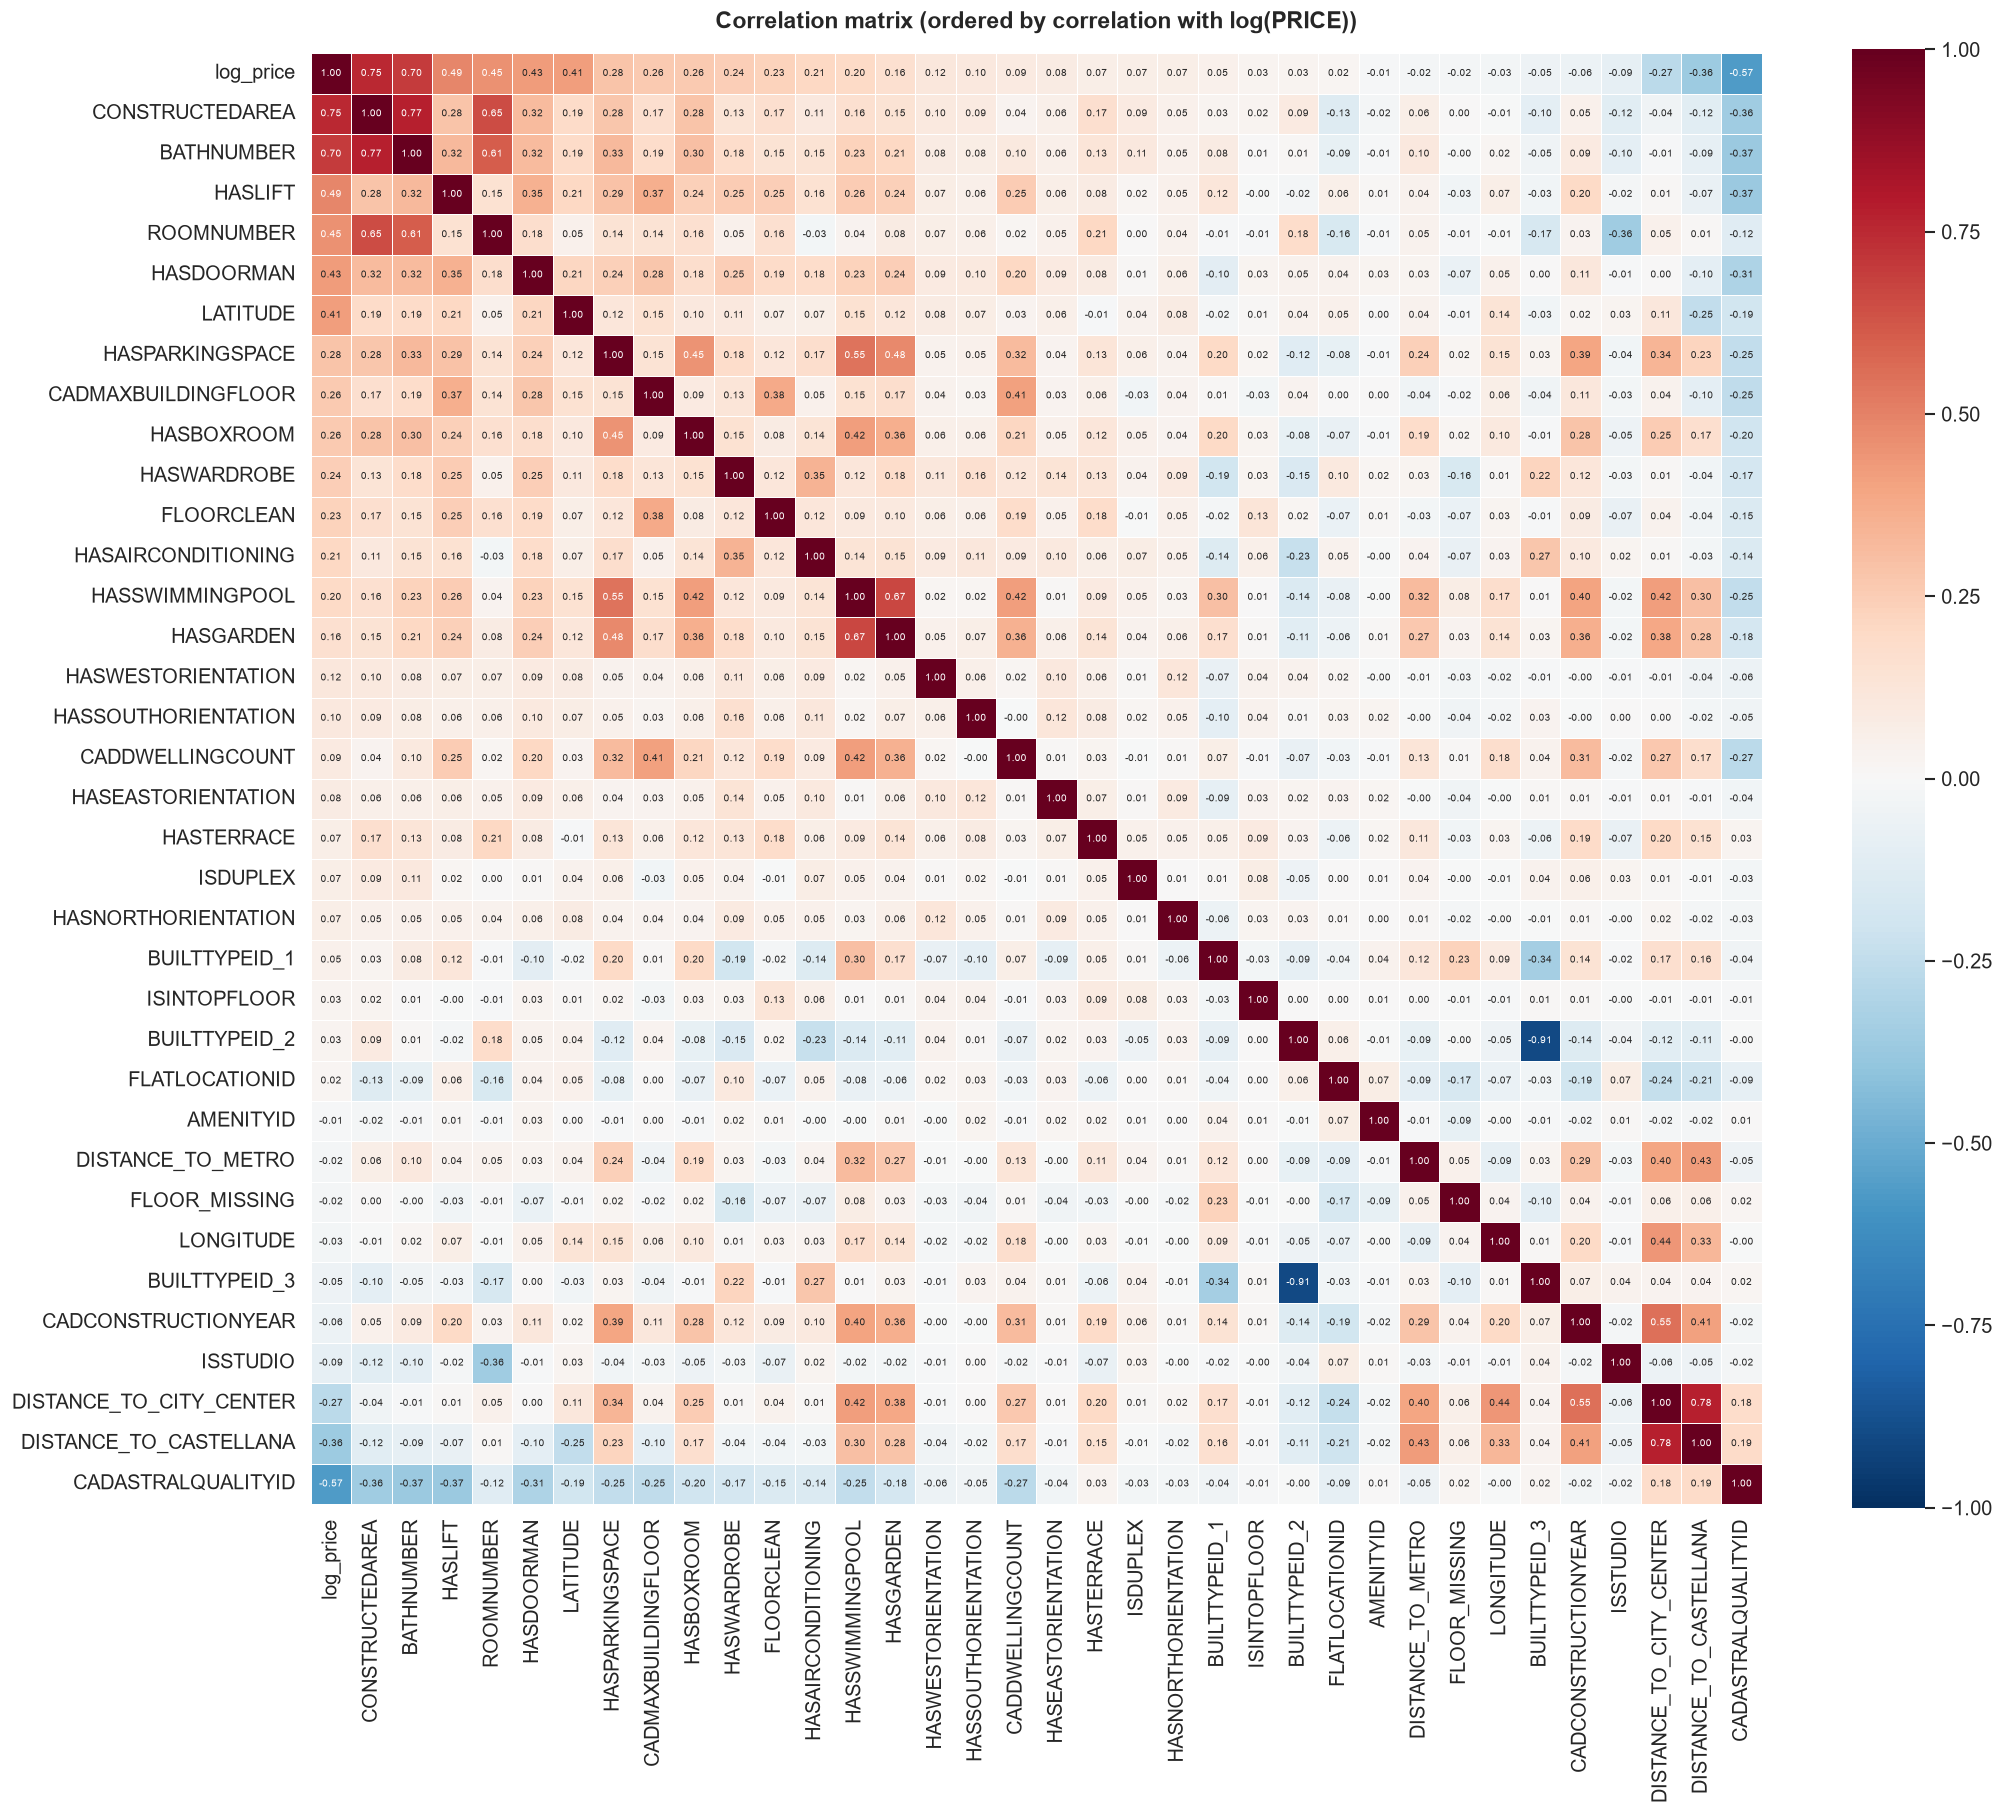

Top 10 features by |correlation| with log(PRICE):
CONSTRUCTEDAREA            0.750
BATHNUMBER                 0.696
CADASTRALQUALITYID         0.570
HASLIFT                    0.492
ROOMNUMBER                 0.455
HASDOORMAN                 0.425
LATITUDE                   0.414
DISTANCE_TO_CASTELLANA     0.360
HASPARKINGSPACE            0.282
DISTANCE_TO_CITY_CENTER    0.271
Name: log_price, dtype: float64

Most correlated pairs of features:
BUILTTYPEID_2            BUILTTYPEID_3             0.906
DISTANCE_TO_CITY_CENTER  DISTANCE_TO_CASTELLANA    0.778
CONSTRUCTEDAREA          BATHNUMBER                0.775
HASSWIMMINGPOOL          HASGARDEN                 0.666
CONSTRUCTEDAREA          ROOMNUMBER                0.652
ROOMNUMBER               BATHNUMBER                0.607
dtype: float64


In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop("PRICE").tolist()
corr = df[numeric_cols].corr()

# Sort by correlation with the target, log(PRICE)
target_corr = corr["log_price"].drop("log_price").sort_values(ascending=False)
ordered_cols = ["log_price"] + target_corr.index.tolist()

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(corr.loc[ordered_cols, ordered_cols], annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, square=True,
            annot_kws={"size": 6}, vmin=-1, vmax=1, linewidths=0.3, linecolor="white")
ax.set_title("Correlation matrix (ordered by correlation with log(PRICE))", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

print("Top 10 features by |correlation| with log(PRICE):")
print(target_corr.abs().sort_values(ascending=False).head(10).round(3))

# Pairs of features that carry almost the same information (multicollinearity)
feat_corr = corr.drop(index="log_price", columns="log_price").abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
print("\nMost correlated pairs of features:")
print(upper.stack().sort_values(ascending=False).head(6).round(3))

Top 10 features by |correlation| with log(PRICE): `CONSTRUCTEDAREA` (0.75), `BATHNUMBER` (0.70), `CADASTRALQUALITYID` (−0.57), `HASLIFT` (0.49), `ROOMNUMBER` (0.46), `HASDOORMAN` (0.43), `LATITUDE` (0.41), `DISTANCE_TO_CASTELLANA` (−0.36), `HASPARKINGSPACE` (0.28) and `DISTANCE_TO_CITY_CENTER` (−0.27).

- **Size** (area, bathrooms, bedrooms) and **building quality** (cadastral quality, lift, doorman) dominate.
- **Location is a north–south effect more than a concentric one:** `LATITUDE` (0.41) and `DISTANCE_TO_CASTELLANA` (−0.36) beat `DISTANCE_TO_CITY_CENTER` (−0.27), while `LONGITUDE` is ≈ 0.
- **Multicollinearity:**
  - `BUILTTYPEID_2`–`BUILTTYPEID_3` (0.91): they are a one-hot encoding of the same variable (exactly one flag per listing), so one must be left out in linear models.
  - `DISTANCE_TO_CITY_CENTER`–`DISTANCE_TO_CASTELLANA` (0.78).
  - `CONSTRUCTEDAREA`–`BATHNUMBER` (0.78), `CONSTRUCTEDAREA`–`ROOMNUMBER` (0.65), `ROOMNUMBER`–`BATHNUMBER` (0.61).
  - `HASSWIMMINGPOOL`–`HASGARDEN` (0.67).
- Weak linear signal (|r| < 0.07): `AMENITYID`, `FLOOR_MISSING`, `CADCONSTRUCTIONYEAR`, `DISTANCE_TO_METRO`, `LONGITUDE`. For construction year this hides a non-linear pattern (section 1).

## 5. Geographic analysis

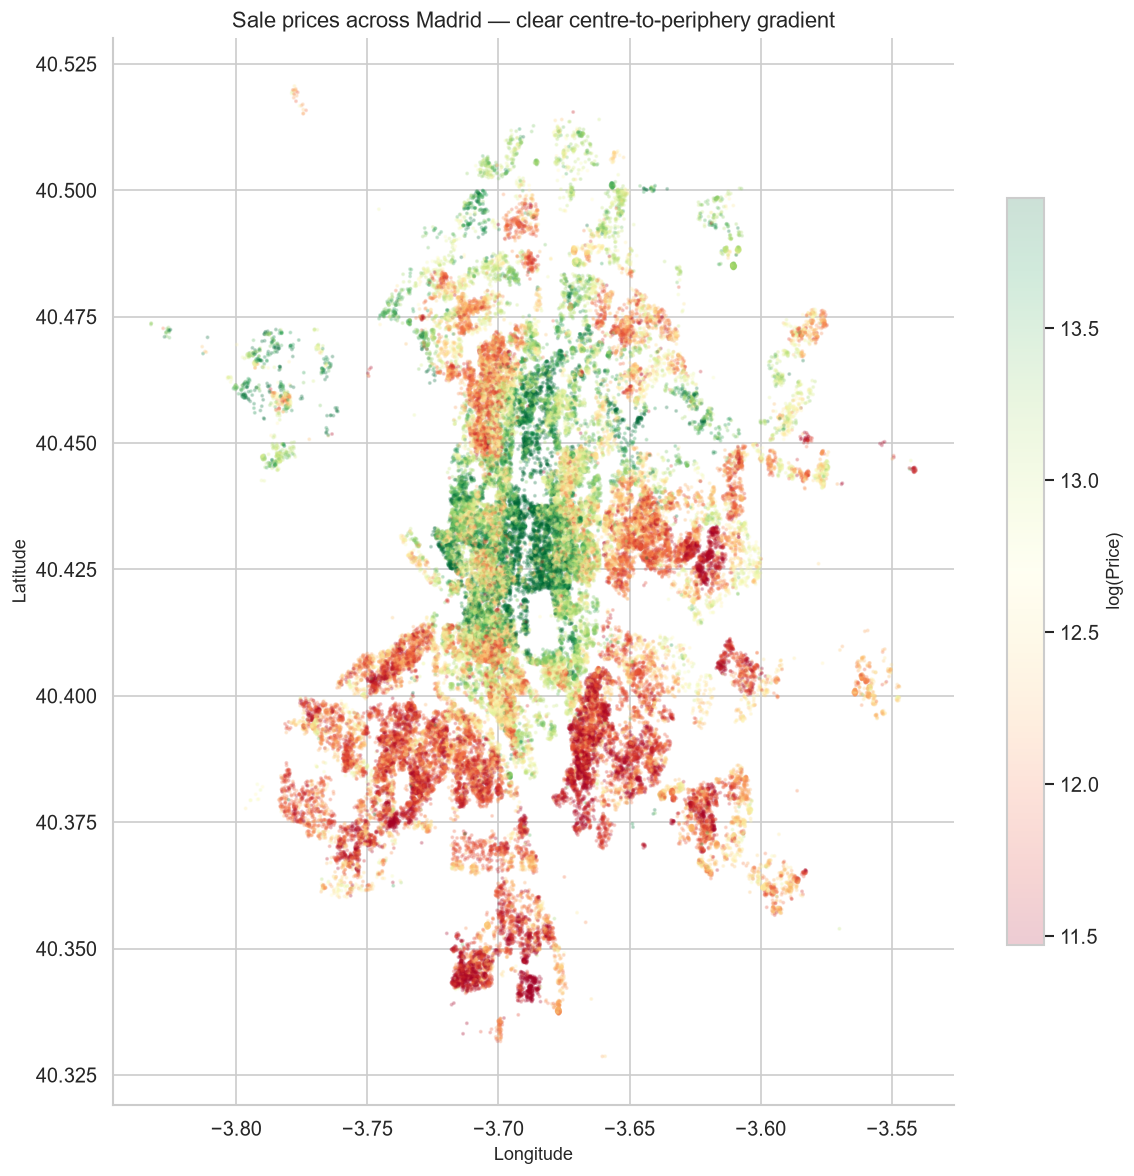

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))
scatter = ax.scatter(df["LONGITUDE"], df["LATITUDE"],
                     c=df["log_price"], cmap="RdYlGn",
                     alpha=0.2, s=2, vmin=df["log_price"].quantile(0.05),
                     vmax=df["log_price"].quantile(0.95))
cbar = plt.colorbar(scatter, ax=ax, label="log(Price)", shrink=0.7)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Sale prices across Madrid — clear centre-to-periphery gradient", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The map shows that the **northern half of the city is clearly more expensive than the southern half**. This is why `LATITUDE` correlates with log(PRICE) (r = 0.41) while `LONGITUDE` does not (≈ 0). The most expensive listings cluster north of the centre around the Paseo de la Castellana axis, which is consistent with `DISTANCE_TO_CASTELLANA` being more informative than distance to the city centre. The spatial pattern is non-linear, so tree-based models (which can combine latitude and longitude) or additional geographic features such as district should help.

## 6. Price trend over 2018

         median_price  median_price_m2  median_area  count
Q1 2018      250000.0           3260.0         85.0  17617
Q2 2018      247000.0           3375.0         80.0  12515
Q3 2018      252000.0           3462.0         80.0  14245
Q4 2018      267500.0           3560.0         82.0  31418

Median price per m², Q1 to Q4 2018: +9.2%


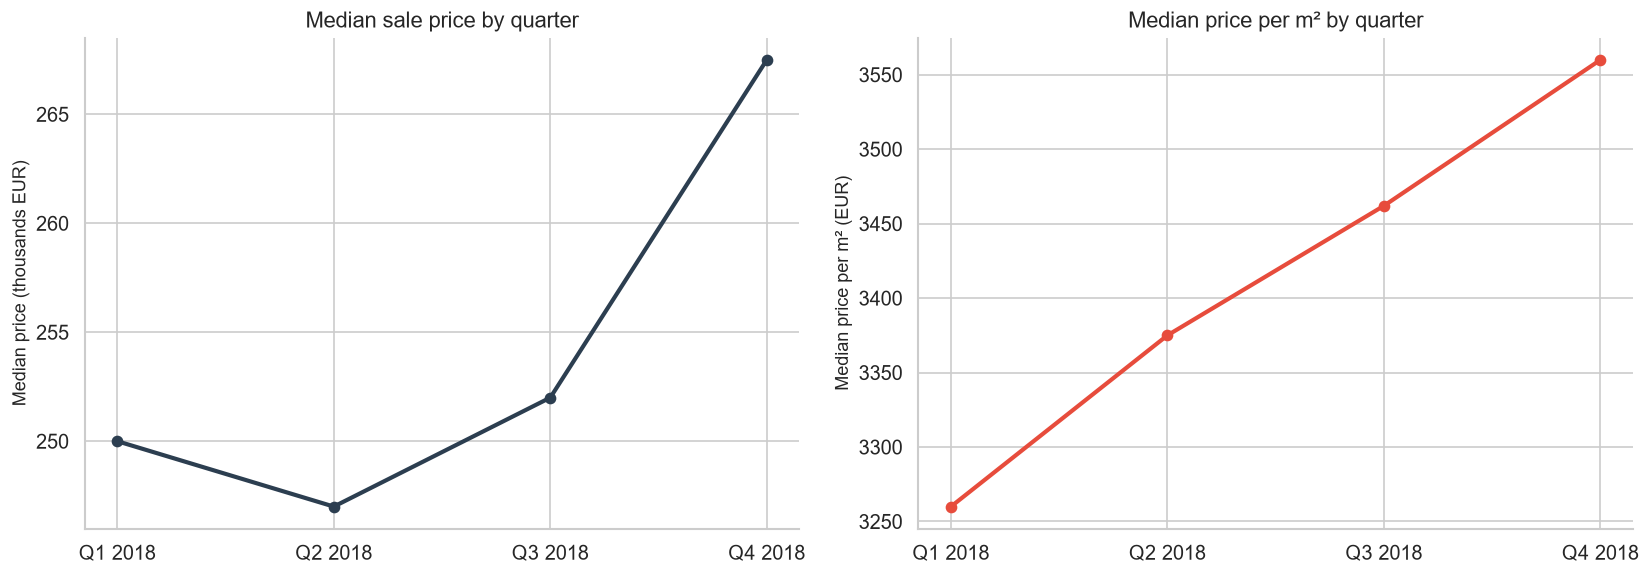

In [7]:
df["PERIOD"] = df["PERIOD"].astype(str)
price_m2 = df["PRICE"] / df["CONSTRUCTEDAREA"]

period_stats = pd.DataFrame({
    "median_price": df.groupby("PERIOD")["PRICE"].median(),
    "median_price_m2": price_m2.groupby(df["PERIOD"]).median().round(0),
    "median_area": df.groupby("PERIOD")["CONSTRUCTEDAREA"].median(),
    "count": df.groupby("PERIOD").size(),
})
period_stats.index = [PERIOD_MAP.get(p, p) for p in period_stats.index]
print(period_stats)

change = period_stats["median_price_m2"].iloc[-1] / period_stats["median_price_m2"].iloc[0] - 1
print(f"\nMedian price per m², Q1 to Q4 2018: {change:+.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(period_stats.index, period_stats["median_price"] / 1000, marker="o", linewidth=2.5, color="#2c3e50")
axes[0].set_ylabel("Median price (thousands EUR)")
axes[0].set_title("Median sale price by quarter")
axes[1].plot(period_stats.index, period_stats["median_price_m2"], marker="o", linewidth=2.5, color="#e74c3c")
axes[1].set_ylabel("Median price per m² (EUR)")
axes[1].set_title("Median price per m² by quarter")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The median *price* barely moves in Q1–Q3 (247k–252k €) and rises in Q4 (267.5k €), but the median **price per m² rises every quarter**: 3,260 → 3,375 → 3,462 → 3,560 €/m² (**+9.2% over 2018**). Madrid sale prices were going up during the year. `PERIOD` should therefore be included as a feature. Because Q4 holds 41.5% of the listings, the period mix also affects any train/test split.

## 7. Conclusions

### Most predictive features (bivariate analysis)

| Rank | Feature | Relationship with log(PRICE) | Strength |
|---|---|---|---|
| 1 | `CONSTRUCTEDAREA` | Positive (r = 0.75) | Very strong |
| 2 | `BATHNUMBER` | Positive (r = 0.70) | Strong |
| 3 | `CADASTRALQUALITYID` | Negative: lower level = more expensive (r = −0.57) | Strong |
| 4 | `HASLIFT` | +134% median price (r = 0.49) | Moderate–strong |
| 5 | `ROOMNUMBER` | Positive, jump from 4 bedrooms (r = 0.46) | Moderate |
| 6 | `HASDOORMAN` | +124% median price (r = 0.43) | Moderate |
| 7 | `LATITUDE` | North more expensive than south (r = 0.41) | Moderate |
| 8 | `DISTANCE_TO_CASTELLANA` | Negative (r = −0.36) | Moderate |
| 9 | `HASPARKINGSPACE` | +75% median price (r = 0.28) | Weak–moderate |
| 10 | `DISTANCE_TO_CITY_CENTER` | Negative (r = −0.27) | Weak–moderate |

Non-linear effects not captured by r: `CADCONSTRUCTIONYEAR` (U-shape) and `FLATLOCATIONID` (unknown = cheapest).

### Recommended feature set for modelling

**Include:** `CONSTRUCTEDAREA`, `ROOMNUMBER`, `BATHNUMBER`, `FLOORCLEAN`, `FLOOR_MISSING`, `FLATLOCATIONID` (categorical, keeping 0 = unknown), `CADCONSTRUCTIONYEAR`, `CADASTRALQUALITYID`, `CADMAXBUILDINGFLOOR`, `CADDWELLINGCOUNT`, `AMENITYID`, all `HAS*`/`IS*` binary features, `BUILTTYPEID_1/2/3` (leave one out in linear models), `DISTANCE_TO_CITY_CENTER`, `DISTANCE_TO_METRO`, `DISTANCE_TO_CASTELLANA`, `LATITUDE`, `LONGITUDE`, `PERIOD`.

**Already excluded in previous notebooks:**
- `UNITPRICE`: target leakage (= PRICE / CONSTRUCTEDAREA), dropped in notebook 01.
- `CONSTRUCTIONYEAR`: 59% missing, replaced by `CADCONSTRUCTIONYEAR`, dropped in notebook 01.
- `PARKINGSPACEPRICE`: placeholder value (1) in almost all listings, dropped in notebook 01.
- `ISPARKINGSPACEINCLUDEDINPRICE`: identical to `HASPARKINGSPACE` in 100% of listings, dropped in notebook 02.

**Not a feature:** `ASSETID` (identifier; duplicates already collapsed to one row per asset in notebook 01).

### Modelling recommendations

1. **Use log(PRICE) as the target:** it is close to normal and linearises the relationship with area.
2. **Expect non-linear effects:** construction year (U-shape), bedrooms (jump at 4+), cadastral quality (rebound at levels 8–9) and location. Tree-based models (random forest, gradient boosting) should outperform a plain linear regression; linear models need bins or one-hot encodings for these variables.
3. **Control multicollinearity** in linear models: size variables (area, bathrooms, bedrooms), the two distance variables and the `BUILTTYPEID` dummies overlap. Use regularisation (Ridge/Lasso) and leave one `BUILTTYPEID` out.
4. **Location is key and mostly north–south:** keep `LATITUDE`, `LONGITUDE` and `DISTANCE_TO_CASTELLANA`.
5. **Binary premiums are not causal:** they are confounded with size and location. Their real contribution has to be measured inside a multivariate model.
6. **Weak features** (`AMENITYID`, `DISTANCE_TO_METRO`, `LONGITUDE` on its own) are kept for now, but they are candidates for removal during feature selection.